# 04 — Covariate relationships with closing-auction volume

This notebook measures how every approved daily covariate relates to `log1p(auction_volume)`.

The analysis separates:

- **Marginal association:** the raw relationship in the pooled panel.
- **Within-stock association:** whether the covariate helps explain changes relative to a stock's own typical level.
- **Year stability:** whether the relationship keeps the same direction over time.
- **Joint association:** standardized ridge coefficients when correlated covariates enter together.

These are descriptive and predictive relationships, not causal estimates.

In [1]:
from pathlib import Path
import json
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 6), "figure.dpi": 120})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")

OUT = PROJECT_ROOT / "outputs" / "eda" / "04_relationships"
OUT.mkdir(parents=True, exist_ok=True)
PANEL = PROJECT_ROOT / "outputs" / "eda" / "03_covariate_audit" / "daily_covariate_panel.parquet"
CATALOG = PROJECT_ROOT / "outputs" / "eda" / "03_covariate_audit" / "approved_daily_features.csv"
if not PANEL.exists():
    raise FileNotFoundError("Run Notebook 03 before Notebook 04.")

con = duckdb.connect()

def sql(query, params=None):
    return con.execute(query, params or []).df()

approved_catalog = pd.read_csv(CATALOG)
display(approved_catalog)
print(f"Canonical panel: {PANEL}")

,variable,group,definition,information_time,classification,approved_daily_feature
0,lag1_auction_volume,Auction history,Previous observed closing-auction volume,Previous close,daily_safe,True
1,lag2_auction_volume,Auction history,Auction volume two trading observations earlier,t-2,daily_safe,True
2,lag5_auction_volume,Auction history,Auction volume five trading observations earlier,t-5,daily_safe,True
3,avg5_auction_volume,Auction history,Mean auction volume over five prior rows,Through t-1,daily_safe,True
4,median20_auction_volume,Auction history,Median auction volume over twenty prior rows,Through t-1,daily_safe,True
5,std20_auction_volume,Auction history,Auction-volume standard deviation over twenty ...,Through t-1,daily_safe,True
6,prior_auction_observations,Auction history,Number of observed prior auctions for the stock,Through t-1,daily_safe,True
7,lag1_daily_volume,Liquidity,Previous trading-day share volume,Previous close,daily_safe,True
8,avg20_daily_volume,Liquidity,Mean daily volume over twenty prior rows,Through t-1,daily_safe,True
9,lag1_return,Returns,Previous trading-day total return,Previous close,daily_safe,True


Canonical panel: /Users/aramesh/Documents/Fall 2026/Capstone/outputs/eda/03_covariate_audit/daily_covariate_panel.parquet


## Transformations used for relationship analysis

Spearman correlations are invariant to monotonic transformations. Pearson, within-stock, and ridge relationships use log transforms for highly skewed positive quantities so that extreme observations do not dominate.

In [2]:
FEATURE_EXPRESSIONS = {
    "lag1_auction_volume": "ln(1 + lag1_auction_volume)",
    "lag2_auction_volume": "ln(1 + lag2_auction_volume)",
    "lag5_auction_volume": "ln(1 + lag5_auction_volume)",
    "avg5_auction_volume": "ln(1 + avg5_auction_volume)",
    "median20_auction_volume": "ln(1 + median20_auction_volume)",
    "std20_auction_volume": "ln(1 + std20_auction_volume)",
    "prior_auction_observations": "ln(1 + prior_auction_observations)",
    "lag1_daily_volume": "ln(1 + lag1_daily_volume)",
    "avg20_daily_volume": "ln(1 + avg20_daily_volume)",
    "lag1_return": "lag1_return",
    "volatility20": "ln(1 + volatility20)",
    "lag1_market_cap": "ln(1 + lag1_market_cap)",
    "size_decile": "size_decile",
    "lag1_market_return": "lag1_market_return",
    "market_volatility20": "ln(1 + market_volatility20)",
    "lag1_market_volume": "ln(1 + lag1_market_volume)",
}

BINARY_FEATURES = [
    "is_monday", "is_friday", "is_last_trading_day_month",
    "is_last_trading_day_quarter", "monthly_options_expiry",
    "quarterly_options_expiry", "is_early_close",
]
CATEGORICAL_FEATURES = ["month", "day_of_week", "ff12_code", "size_decile"]

transform_table = pd.DataFrame({
    "feature": list(FEATURE_EXPRESSIONS),
    "analysis_expression": list(FEATURE_EXPRESSIONS.values()),
})
display(transform_table)
transform_table.to_csv(OUT / "relationship_transformations.csv", index=False)

,feature,analysis_expression
0,lag1_auction_volume,ln(1 + lag1_auction_volume)
1,lag2_auction_volume,ln(1 + lag2_auction_volume)
2,lag5_auction_volume,ln(1 + lag5_auction_volume)
3,avg5_auction_volume,ln(1 + avg5_auction_volume)
4,median20_auction_volume,ln(1 + median20_auction_volume)
5,std20_auction_volume,ln(1 + std20_auction_volume)
6,prior_auction_observations,ln(1 + prior_auction_observations)
7,lag1_daily_volume,ln(1 + lag1_daily_volume)
8,avg20_daily_volume,ln(1 + avg20_daily_volume)
9,lag1_return,lag1_return


## Draw a fixed analytical sample for rank relationships and plots

In [3]:
select_parts = ["date", "year", "permno", "log1p_auction_volume"]
select_parts += [f"{expr} AS {feature}" for feature, expr in FEATURE_EXPRESSIONS.items()]
select_parts += BINARY_FEATURES + ["month", "day_of_week", "ff12_code"]

sample = sql(f"""
SELECT {', '.join(select_parts)}
FROM read_parquet('{PANEL}')
WHERE eligible_target
USING SAMPLE 500000 ROWS (reservoir, 20261011)
""")
print(f"Sample rows: {len(sample):,}; stocks: {sample.permno.nunique():,}; dates: {sample.date.nunique():,}")

Sample rows: 486,805; stocks: 2,145; dates: 2,765


## Marginal and within-stock numeric relationships

In [4]:
# Sample Spearman correlations.
spearman = sample[list(FEATURE_EXPRESSIONS) + ["log1p_auction_volume"]].rank(pct=True).corr()
marginal_spearman = spearman["log1p_auction_volume"].drop("log1p_auction_volume")

# Full-panel pooled and within-stock Pearson correlations on transformed values.
feature_select = ",\n       ".join(
    f"{expr} AS {feature}" for feature, expr in FEATURE_EXPRESSIONS.items()
)
stock_means = ",\n       ".join(
    f"avg({feature}) OVER (PARTITION BY permno) AS mean_{feature}"
    for feature in FEATURE_EXPRESSIONS
)
aggregate_parts = []
for feature in FEATURE_EXPRESSIONS:
    aggregate_parts.extend([
        f"corr({feature}, y) AS pooled__{feature}",
        f"corr({feature} - mean_{feature}, y - mean_y) AS within__{feature}",
    ])

relationship_wide = sql(f"""
WITH base AS (
    SELECT date, permno, log1p_auction_volume AS y,
           {feature_select}
    FROM read_parquet('{PANEL}')
    WHERE eligible_target
), demeaned AS (
    SELECT *, avg(y) OVER (PARTITION BY permno) AS mean_y,
           {stock_means}
    FROM base
)
SELECT {', '.join(aggregate_parts)} FROM demeaned
""")

records = []
for feature in FEATURE_EXPRESSIONS:
    records.append({
        "feature": feature,
        "marginal_spearman": marginal_spearman[feature],
        "pooled_pearson_transformed": relationship_wide.loc[0, f"pooled__{feature}"],
        "within_stock_pearson": relationship_wide.loc[0, f"within__{feature}"],
    })
numeric_relationships = pd.DataFrame(records)
display(numeric_relationships.sort_values("within_stock_pearson", key=lambda s: s.abs(), ascending=False))

,feature,marginal_spearman,pooled_pearson_transformed,within_stock_pearson
4,median20_auction_volume,0.9211,0.9284,0.6818
3,avg5_auction_volume,0.8958,0.9072,0.6112
0,lag1_auction_volume,0.8814,0.8913,0.5837
1,lag2_auction_volume,0.8751,0.8852,0.5602
2,lag5_auction_volume,0.8664,0.8770,0.5289
8,avg20_daily_volume,0.8340,0.8313,0.4481
7,lag1_daily_volume,0.8319,0.8284,0.4376
5,std20_auction_volume,0.7778,0.8000,0.3622
6,prior_auction_observations,0.2813,0.2637,0.3592
11,lag1_market_cap,0.6557,0.6635,0.2462


## Stability across years

,feature,marginal_spearman,pooled_pearson_transformed,within_stock_pearson,min_year_correlation,max_year_correlation,mean_year_correlation,year_correlation_std,same_sign_all_years,absolute_within_stock
4,median20_auction_volume,0.9211,0.9284,0.6818,0.9020,0.9381,0.9155,0.0137,True,0.6818
3,avg5_auction_volume,0.8958,0.9072,0.6112,0.8673,0.9210,0.8893,0.0172,True,0.6112
0,lag1_auction_volume,0.8814,0.8913,0.5837,0.8455,0.9143,0.8748,0.0259,True,0.5837
1,lag2_auction_volume,0.8751,0.8852,0.5602,0.8402,0.9064,0.8675,0.0248,True,0.5602
2,lag5_auction_volume,0.8664,0.8770,0.5289,0.8420,0.8963,0.8576,0.0207,True,0.5289
8,avg20_daily_volume,0.8340,0.8313,0.4481,0.7945,0.8904,0.8516,0.0269,True,0.4481
7,lag1_daily_volume,0.8319,0.8284,0.4376,0.8027,0.8903,0.8492,0.0246,True,0.4376
5,std20_auction_volume,0.7778,0.8000,0.3622,0.7521,0.8070,0.7736,0.0168,True,0.3622
6,prior_auction_observations,0.2813,0.2637,0.3592,0.0399,0.2031,0.1337,0.0523,True,0.3592
11,lag1_market_cap,0.6557,0.6635,0.2462,0.6087,0.6987,0.6600,0.0344,True,0.2462


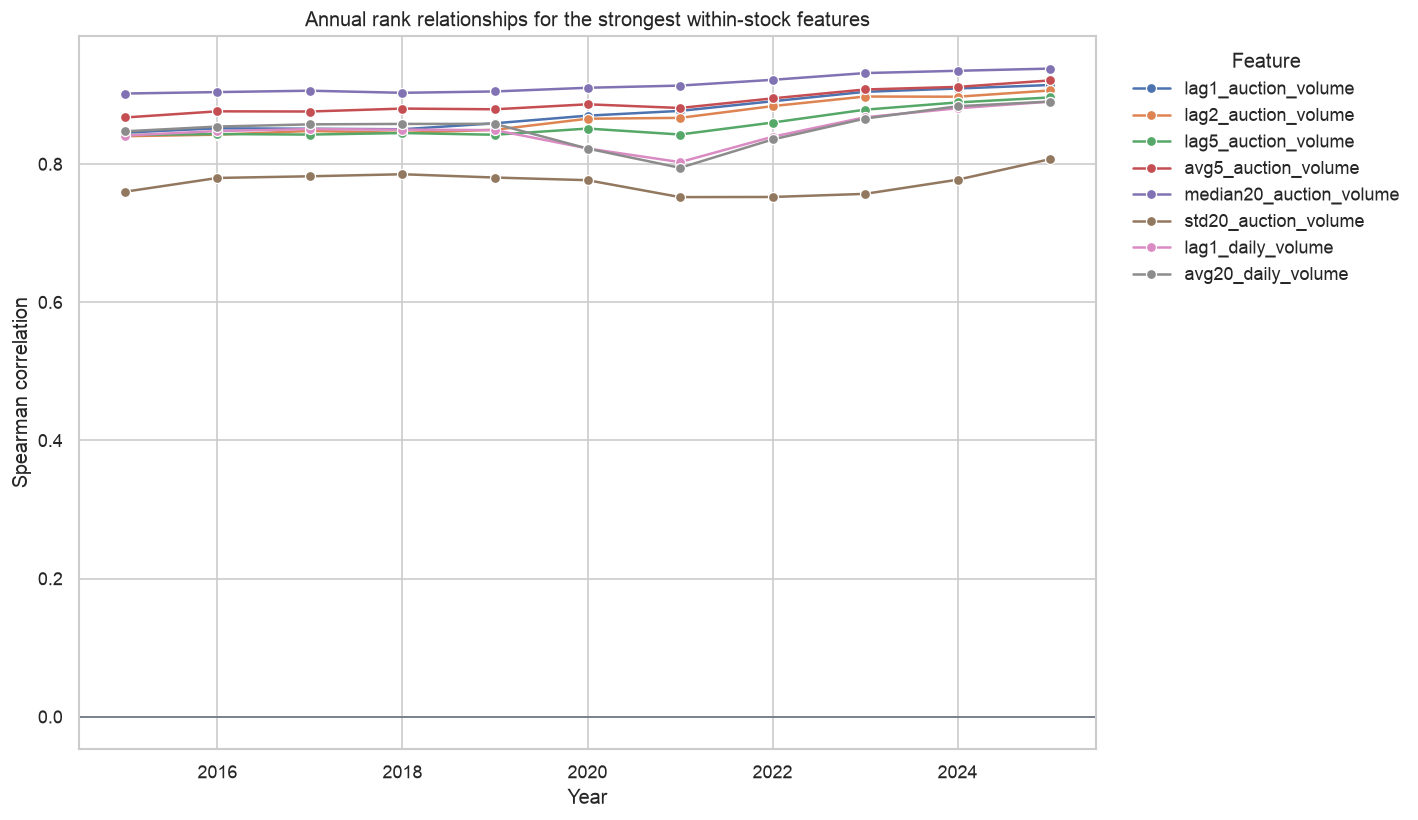

In [5]:
yearly_rows = []
for year, group in sample.groupby("year"):
    corr = group[list(FEATURE_EXPRESSIONS) + ["log1p_auction_volume"]].rank(pct=True).corr()["log1p_auction_volume"]
    for feature in FEATURE_EXPRESSIONS:
        yearly_rows.append({"year": int(year), "feature": feature, "spearman": corr[feature]})
yearly_relationships = pd.DataFrame(yearly_rows)
yearly_relationships.to_csv(OUT / "numeric_relationships_by_year.csv", index=False)

stability = yearly_relationships.groupby("feature")["spearman"].agg(
    min_year_correlation="min",
    max_year_correlation="max",
    mean_year_correlation="mean",
    year_correlation_std="std",
)
stability["same_sign_all_years"] = (
    (stability["min_year_correlation"] > 0) | (stability["max_year_correlation"] < 0)
)
numeric_relationships = numeric_relationships.merge(stability.reset_index(), on="feature", how="left")
numeric_relationships["absolute_within_stock"] = numeric_relationships["within_stock_pearson"].abs()
numeric_relationships = numeric_relationships.sort_values("absolute_within_stock", ascending=False)
display(numeric_relationships)
numeric_relationships.to_csv(OUT / "numeric_relationship_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 7))
plot_year = yearly_relationships[yearly_relationships["feature"].isin(numeric_relationships.head(8)["feature"])]
sns.lineplot(data=plot_year, x="year", y="spearman", hue="feature", marker="o", ax=ax)
ax.axhline(0, color="#6b7280", linewidth=1)
ax.set(title="Annual rank relationships for the strongest within-stock features", xlabel="Year", ylabel="Spearman correlation")
ax.legend(title="Feature", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(OUT / "relationship_stability_by_year.png", bbox_inches="tight")
plt.show()

## Covariate-decile target curves

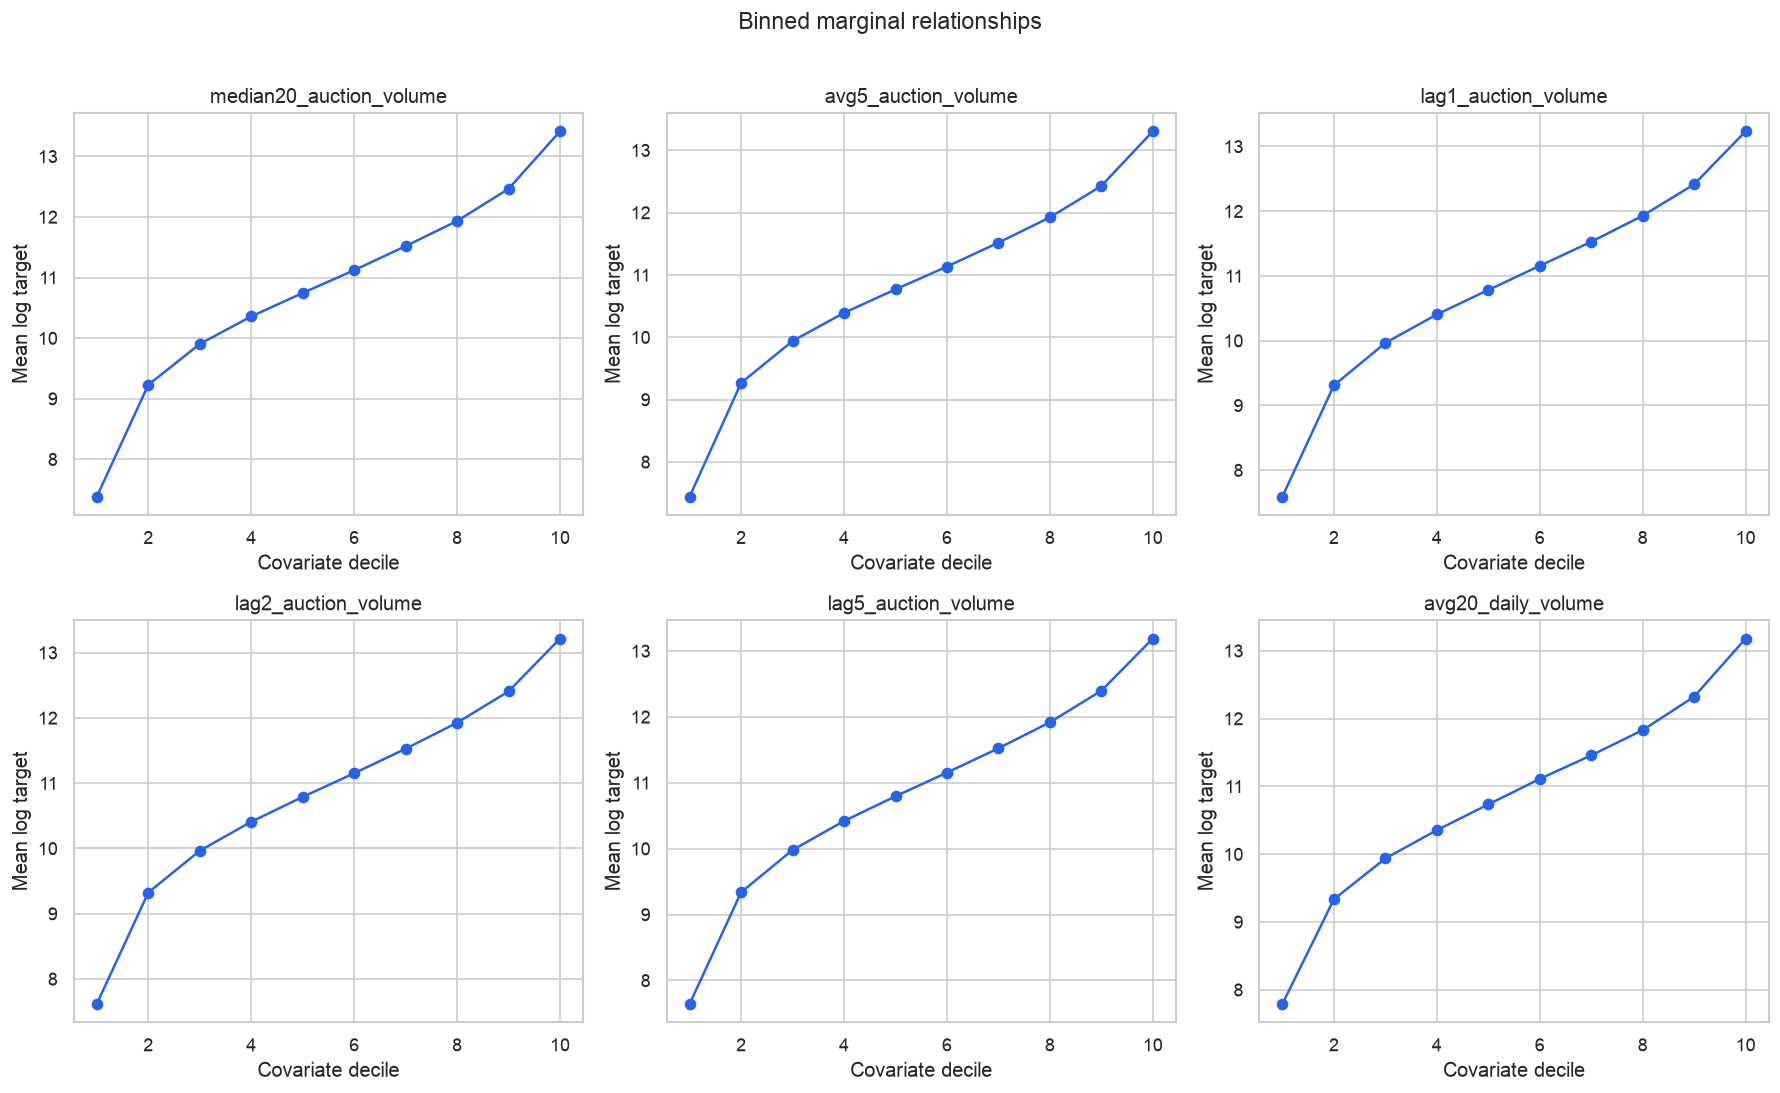

In [6]:
bin_rows = []
for feature in FEATURE_EXPRESSIONS:
    valid = sample[[feature, "log1p_auction_volume"]].dropna().copy()
    try:
        valid["bin"] = pd.qcut(valid[feature], 10, labels=False, duplicates="drop") + 1
    except ValueError:
        continue
    grouped = valid.groupby("bin", observed=True).agg(
        observations=("log1p_auction_volume", "size"),
        mean_target=("log1p_auction_volume", "mean"),
        median_feature=(feature, "median"),
    ).reset_index()
    grouped["feature"] = feature
    bin_rows.append(grouped)
bin_curves = pd.concat(bin_rows, ignore_index=True)
bin_curves.to_csv(OUT / "numeric_decile_curves.csv", index=False)

top_features = numeric_relationships.head(6)["feature"].tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=False)
for ax, feature in zip(axes.flat, top_features):
    d = bin_curves[bin_curves["feature"] == feature]
    ax.plot(d["bin"], d["mean_target"], marker="o", color="#2563eb")
    ax.set(title=feature, xlabel="Covariate decile", ylabel="Mean log target")
fig.suptitle("Binned marginal relationships", y=1.01, fontsize=14)
fig.tight_layout()
fig.savefig(OUT / "top_numeric_decile_curves.png", bbox_inches="tight")
plt.show()

## Binary calendar effects

,feature,mean_log_difference_true_minus_false,median_raw_ratio_true_to_false,median_adv_ratio_true_to_false,true_observations
6,quarterly_options_expiry,1.9076,6.8991,6.6364,56061
5,monthly_options_expiry,0.6864,1.9200,1.5949,167559
3,is_last_trading_day_quarter,0.6003,1.8540,1.7123,55873
2,is_last_trading_day_month,0.5994,1.8228,1.8188,167728
1,is_friday,0.2178,1.1939,1.1284,702860
4,is_monday,-0.0366,0.9699,0.9872,653074
0,is_early_close,-0.6310,0.5145,0.4766,28756


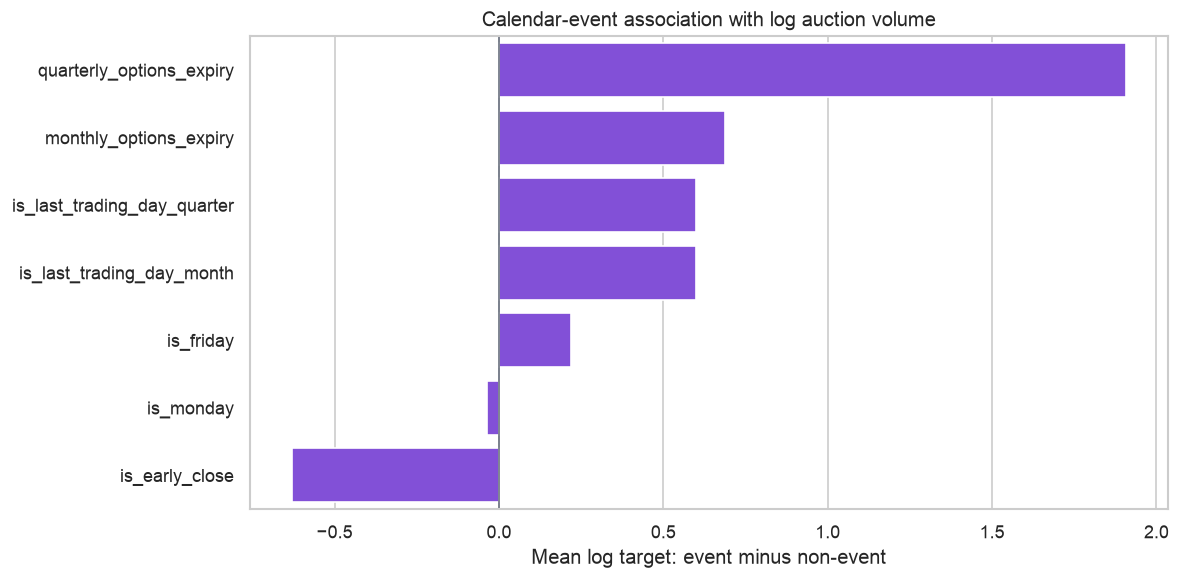

In [7]:
binary_queries = []
for feature in BINARY_FEATURES:
    binary_queries.append(f"""
      SELECT '{feature}' AS feature, cast({feature} AS BOOLEAN) AS category,
             count(*) AS observations,
             avg(log1p_auction_volume) AS mean_log_target,
             median(auction_volume) AS median_raw_target,
             median(auction_to_adv20) AS median_target_to_adv
      FROM read_parquet('{PANEL}')
      WHERE eligible_target GROUP BY {feature}
    """)
binary_groups = sql(" UNION ALL ".join(binary_queries))

effect_rows = []
for feature, group in binary_groups.groupby("feature"):
    indexed = group.set_index("category")
    if True in indexed.index and False in indexed.index:
        effect_rows.append({
            "feature": feature,
            "mean_log_difference_true_minus_false": indexed.loc[True, "mean_log_target"] - indexed.loc[False, "mean_log_target"],
            "median_raw_ratio_true_to_false": indexed.loc[True, "median_raw_target"] / indexed.loc[False, "median_raw_target"],
            "median_adv_ratio_true_to_false": indexed.loc[True, "median_target_to_adv"] / indexed.loc[False, "median_target_to_adv"],
            "true_observations": indexed.loc[True, "observations"],
        })
binary_effects = pd.DataFrame(effect_rows).sort_values("mean_log_difference_true_minus_false", ascending=False)
display(binary_effects)
binary_groups.to_csv(OUT / "binary_feature_groups.csv", index=False)
binary_effects.to_csv(OUT / "binary_feature_effects.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=binary_effects, y="feature", x="mean_log_difference_true_minus_false", color="#7c3aed", ax=ax)
ax.axvline(0, color="#6b7280", linewidth=1)
ax.set(title="Calendar-event association with log auction volume", xlabel="Mean log target: event minus non-event", ylabel="")
fig.tight_layout()
fig.savefig(OUT / "binary_calendar_effects.png", bbox_inches="tight")
plt.show()

## Month, weekday, industry, and size relationships

,feature,category,observations,mean_log_target,median_raw_target,median_target_to_adv
0,month,1,281651,10.7559,"52,148.0000",0.0789
1,month,2,267711,10.7393,"52,518.0000",0.0732
2,month,3,305614,10.9176,"61,367.0000",0.0774
3,month,4,286979,10.7448,"52,532.0000",0.0705
4,month,5,294524,10.7526,"52,150.0000",0.0724
5,month,6,294067,10.9675,"63,264.0000",0.0843
6,month,7,293647,10.7244,"52,131.0000",0.0708
7,month,8,307493,10.6585,"48,616.0000",0.0717
8,month,9,284677,10.8950,"60,575.0000",0.0912
9,month,10,306706,10.7587,"53,756.0000",0.0786


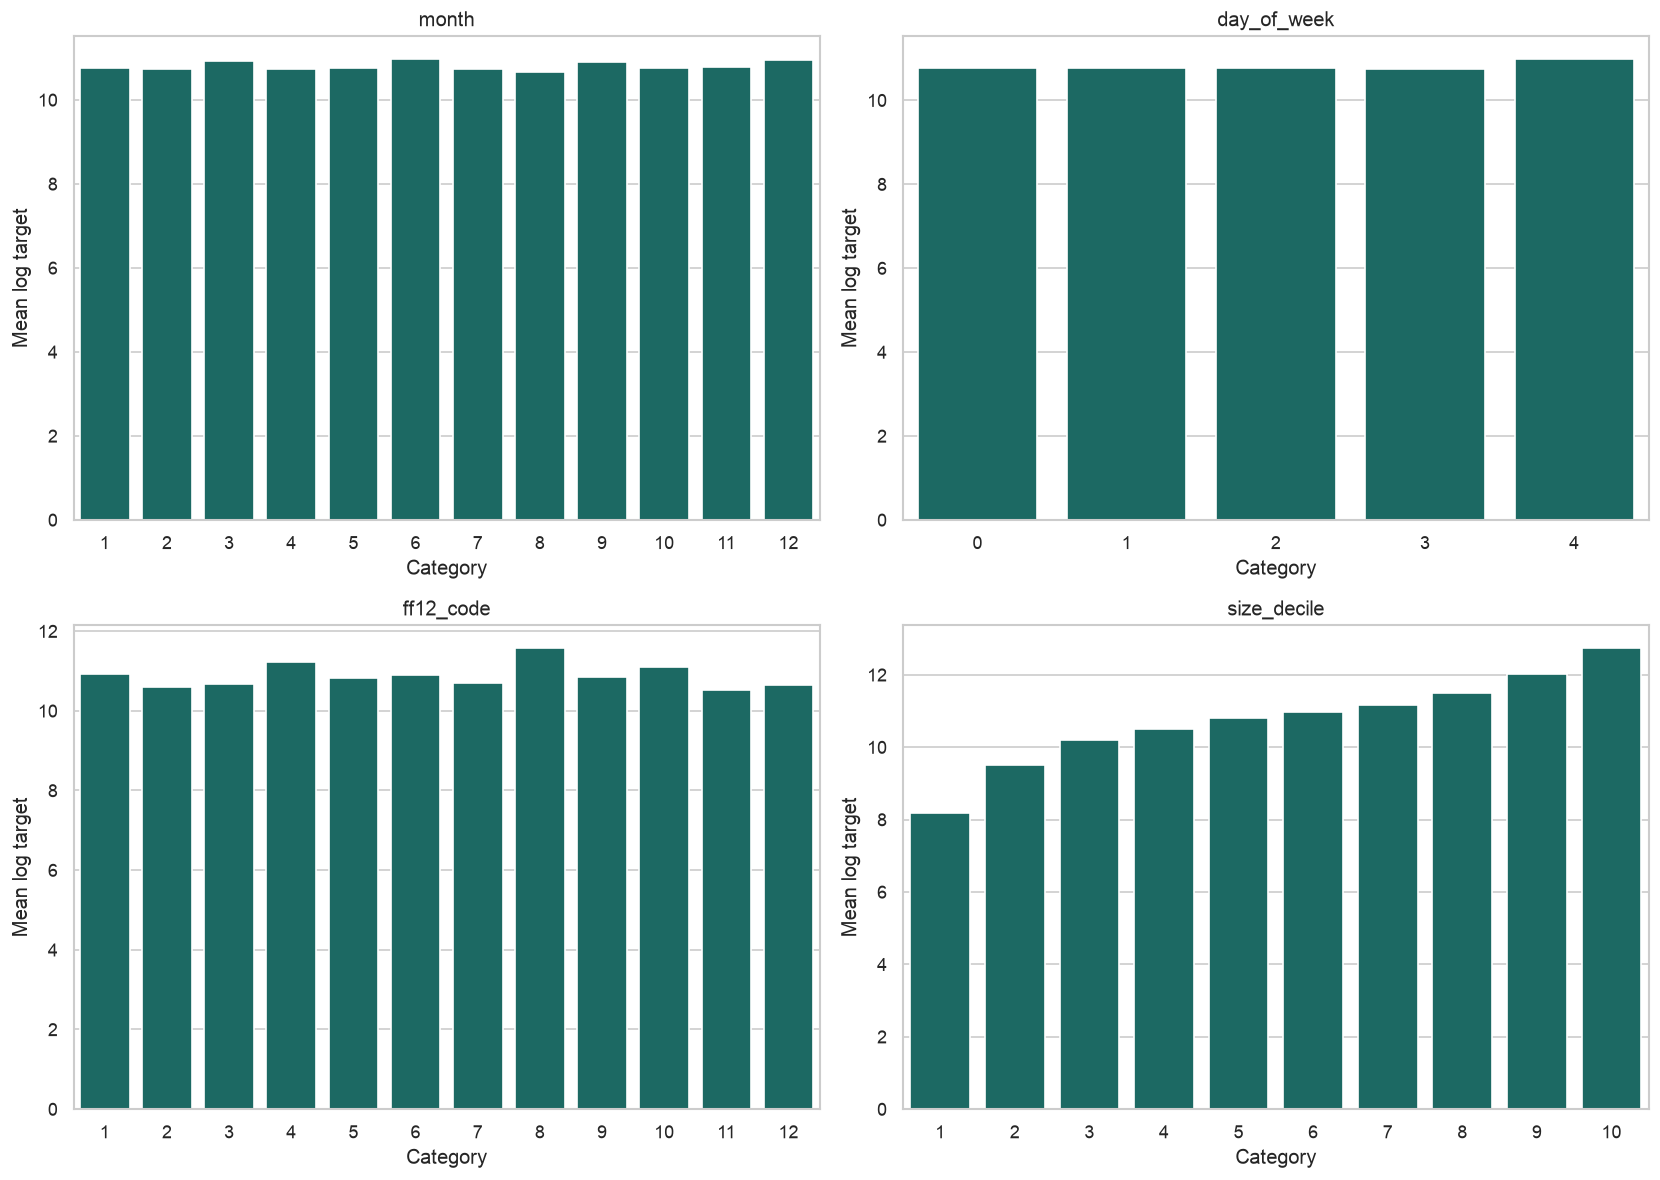

In [8]:
category_queries = []
for feature in CATEGORICAL_FEATURES:
    category_queries.append(f"""
      SELECT '{feature}' AS feature, cast({feature} AS VARCHAR) AS category,
             count(*) AS observations,
             avg(log1p_auction_volume) AS mean_log_target,
             median(auction_volume) AS median_raw_target,
             median(auction_to_adv20) AS median_target_to_adv
      FROM read_parquet('{PANEL}')
      WHERE eligible_target GROUP BY {feature}
    """)
categorical_relationships = sql(" UNION ALL ".join(category_queries))
display(categorical_relationships)
categorical_relationships.to_csv(OUT / "categorical_relationships.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, feature in zip(axes.flat, CATEGORICAL_FEATURES):
    d = categorical_relationships[categorical_relationships["feature"] == feature].copy()
    if feature in {"month", "day_of_week", "size_decile", "ff12_code"}:
        d["order"] = pd.to_numeric(d["category"], errors="coerce")
        d = d.sort_values("order")
    sns.barplot(data=d, x="category", y="mean_log_target", color="#0f766e", ax=ax)
    ax.set(title=feature, xlabel="Category", ylabel="Mean log target")
fig.tight_layout()
fig.savefig(OUT / "categorical_target_relationships.png", bbox_inches="tight")
plt.show()

## Joint within-stock relationship using ridge regression

This diagnostic enters the continuous and binary covariates together after demeaning them within each stock. Ridge regularization stabilizes coefficients in the presence of the strong redundancy found in Notebook 03. Coefficients are standardized directional signals, not causal effects or final model importance.

,feature,within_stock_ridge_coefficient,absolute_coefficient
4,median20_auction_volume,0.4271,0.4271
21,quarterly_options_expiry,0.2400,0.2400
18,is_last_trading_day_month,0.1739,0.1739
7,lag1_daily_volume,0.1365,0.1365
3,avg5_auction_volume,0.0889,0.0889
22,is_early_close,-0.0808,0.0808
0,lag1_auction_volume,0.0677,0.0677
11,lag1_market_cap,0.0636,0.0636
1,lag2_auction_volume,0.0586,0.0586
6,prior_auction_observations,0.0582,0.0582


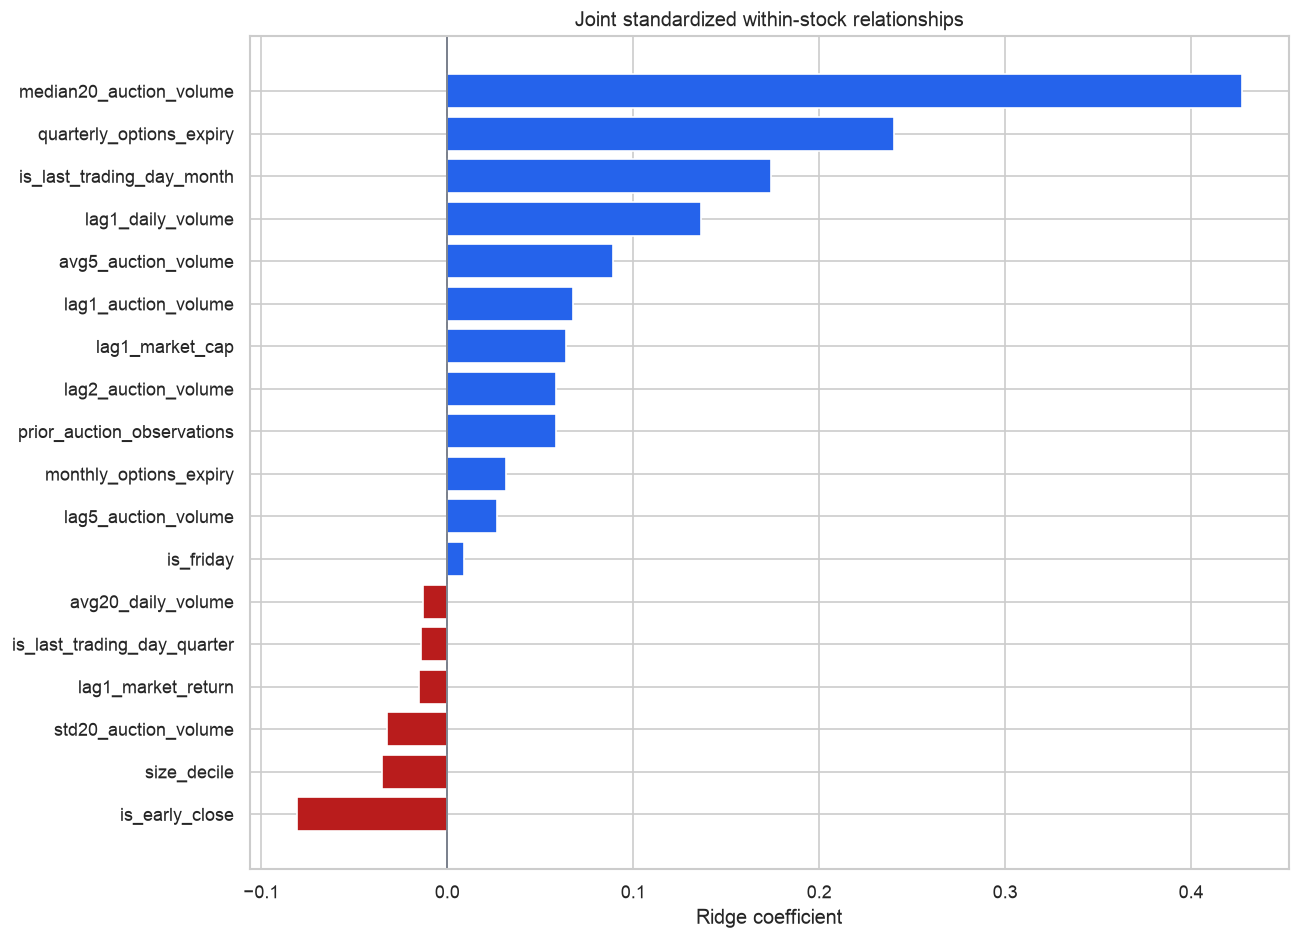

In [9]:
RIDGE_FEATURES = list(FEATURE_EXPRESSIONS) + BINARY_FEATURES
ridge_data = sample[["permno", "log1p_auction_volume"] + RIDGE_FEATURES].copy()

# Median imputation is diagnostic here; final models will also receive explicit missing indicators.
for feature in RIDGE_FEATURES:
    if ridge_data[feature].isna().any():
        ridge_data[feature] = ridge_data[feature].fillna(ridge_data[feature].median())
    ridge_data[feature] = ridge_data[feature].astype(float)

y = ridge_data["log1p_auction_volume"]
X = ridge_data[RIDGE_FEATURES]
y_within = y - y.groupby(ridge_data["permno"]).transform("mean")
X_within = X - X.groupby(ridge_data["permno"]).transform("mean")

scale = X_within.std().replace(0, np.nan)
usable = scale[scale.notna() & (scale > 0)].index.tolist()
X_std = (X_within[usable] / scale[usable]).fillna(0.0)
y_std = y_within / y_within.std()

X_np = X_std.to_numpy(dtype=np.float64)
y_np = y_std.to_numpy(dtype=np.float64)
ridge_lambda = 10.0
coef = np.linalg.solve(X_np.T @ X_np + ridge_lambda * np.eye(X_np.shape[1]), X_np.T @ y_np)
ridge = pd.DataFrame({"feature": usable, "within_stock_ridge_coefficient": coef})
ridge["absolute_coefficient"] = ridge["within_stock_ridge_coefficient"].abs()
ridge = ridge.sort_values("absolute_coefficient", ascending=False)
display(ridge)
ridge.to_csv(OUT / "joint_within_stock_ridge_coefficients.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 8))
plot_ridge = ridge.head(18).sort_values("within_stock_ridge_coefficient")
colors = np.where(plot_ridge["within_stock_ridge_coefficient"] >= 0, "#2563eb", "#b91c1c")
ax.barh(plot_ridge["feature"], plot_ridge["within_stock_ridge_coefficient"], color=colors)
ax.axvline(0, color="#6b7280", linewidth=1)
ax.set(title="Joint standardized within-stock relationships", xlabel="Ridge coefficient", ylabel="")
fig.tight_layout()
fig.savefig(OUT / "joint_within_stock_ridge_coefficients.png", bbox_inches="tight")
plt.show()

## Consolidated relationship ranking

In [10]:
summary = numeric_relationships.merge(
    ridge[["feature", "within_stock_ridge_coefficient"]], on="feature", how="left"
)
summary["marginal_strength"] = pd.cut(
    summary["marginal_spearman"].abs(),
    bins=[-np.inf, 0.10, 0.30, 0.60, np.inf],
    labels=["Weak", "Moderate", "Strong", "Very strong"],
)
summary["within_stock_strength"] = pd.cut(
    summary["within_stock_pearson"].abs(),
    bins=[-np.inf, 0.05, 0.15, 0.30, np.inf],
    labels=["Weak", "Moderate", "Strong", "Very strong"],
)
summary = summary.sort_values("absolute_within_stock", ascending=False)
display(summary)
summary.to_csv(OUT / "consolidated_numeric_relationships.csv", index=False)

,feature,marginal_spearman,pooled_pearson_transformed,within_stock_pearson,min_year_correlation,max_year_correlation,mean_year_correlation,year_correlation_std,same_sign_all_years,absolute_within_stock,within_stock_ridge_coefficient,marginal_strength,within_stock_strength
0,median20_auction_volume,0.9211,0.9284,0.6818,0.9020,0.9381,0.9155,0.0137,True,0.6818,0.4271,Very strong,Very strong
1,avg5_auction_volume,0.8958,0.9072,0.6112,0.8673,0.9210,0.8893,0.0172,True,0.6112,0.0889,Very strong,Very strong
2,lag1_auction_volume,0.8814,0.8913,0.5837,0.8455,0.9143,0.8748,0.0259,True,0.5837,0.0677,Very strong,Very strong
3,lag2_auction_volume,0.8751,0.8852,0.5602,0.8402,0.9064,0.8675,0.0248,True,0.5602,0.0586,Very strong,Very strong
4,lag5_auction_volume,0.8664,0.8770,0.5289,0.8420,0.8963,0.8576,0.0207,True,0.5289,0.0268,Very strong,Very strong
5,avg20_daily_volume,0.8340,0.8313,0.4481,0.7945,0.8904,0.8516,0.0269,True,0.4481,-0.0128,Very strong,Very strong
6,lag1_daily_volume,0.8319,0.8284,0.4376,0.8027,0.8903,0.8492,0.0246,True,0.4376,0.1365,Very strong,Very strong
7,std20_auction_volume,0.7778,0.8000,0.3622,0.7521,0.8070,0.7736,0.0168,True,0.3622,-0.0323,Very strong,Very strong
8,prior_auction_observations,0.2813,0.2637,0.3592,0.0399,0.2031,0.1337,0.0523,True,0.3592,0.0582,Moderate,Very strong
9,lag1_market_cap,0.6557,0.6635,0.2462,0.6087,0.6987,0.6600,0.0344,True,0.2462,0.0636,Very strong,Strong


## Interpretation rules for the next modeling step

1. High marginal but weaker within-stock relationships primarily distinguish large, liquid stocks from small stocks.
2. Strong within-stock relationships indicate variables that help explain whether a particular stock's auction is unusually large that day.
3. Ridge coefficients are used only to understand redundancy and conditional direction. Predictive importance will be established through out-of-time baseline tests.
4. Calendar variables are evaluated at the date level because every stock shares the same value on a given date.
5. Variables whose sign changes materially across years require interactions, nonlinear models, or cautious interpretation.
6. Notebook 05 will test whether these relationships produce improvement over lag-1 and rolling-median baselines.